# Ablation Study 2: CNN + BiLSTM Only (No Transformer)

This notebook removes the **Transformer** component and keeps CNN + BiLSTM.

In [8]:
# Fix PyTorch for Kaggle P100 (CUDA 6.0 / sm_60)
# The default Kaggle PyTorch does NOT support P100 (sm_60).
# We install the last PyTorch that still supports sm_60.
import subprocess, sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "torch==1.13.1+cu116", "torchvision==0.14.1+cu116",
     "--extra-index-url", "https://download.pytorch.org/whl/cu116"],
    capture_output=True, text=True
)
print(result.stdout[-500:] if result.stdout else "")
print(result.stderr[-500:] if result.stderr else "")
print("Done. Restart kernel NOW if this was not already installed.")


ERROR: Could not find a version that satisfies the requirement torch==1.13.1+cu116 (from versions: 2.2.0, 2.2.1, 2.2.2, 2.3.0, 2.3.1, 2.4.0, 2.4.1, 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0)
ERROR: No matching distribution found for torch==1.13.1+cu116

Done. Restart kernel NOW if this was not already installed.


In [14]:
import torch
# After the PyTorch reinstall above, cuda should now work on P100
# If cuda is still unavailable for any reason, we gracefully fall back to CPU
if torch.cuda.is_available():
    try:
        # quick smoke-test: a tiny tensor op on GPU
        _ = torch.zeros(1).cuda()
        device = torch.device("cuda")
        print(f"Using GPU: {torch.cuda.get_device_name(0)}")
    except Exception as e:
        print(f"GPU test failed ({e}), falling back to CPU.")
        device = torch.device("cpu")
else:
    device = torch.device("cpu")
    print("CUDA not available — running on CPU.")
print(f"Device: {device}")

Using GPU: Tesla T4
Device: cuda


In [1]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

In [5]:
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (46, 1),
    'dataset_path': '/kaggle/input/datasets/himadri07/ciciot2023/CICIOT23',
}

ATTACK_MAPPING = {
    'DoS-TCP_Flood': 'DoS_TCP_Flood',
    'DoS-SYN_Flood': 'DoS_SYN_Flood',
    'DoS-HTTP_Flood': 'DoS_HTTP_Flood',
    'DoS-UDP_Flood': 'DoS',
    'DDoS-TCP_Flood': 'DDoS',
    'DDoS-PSHACK_Flood': 'DDoS',
    'DDoS-SYN_Flood': 'DDoS',
    'DDoS-RSTFINFlood': 'DDoS',
    'DDoS-SynonymousIP_Flood': 'DDoS',
    'DDoS-ACK_Fragmentation': 'DDoS_ACK_Fragmentation',
    'DDoS-HTTP_Flood': 'DDoS',
    'DDoS-SlowLoris': 'DDoS',
    'DDoS-UDP_Flood': 'DDoS',
    'DDoS-ICMP_Flood': 'DDoS',
    'DDoS-UDP_Fragmentation': 'DDoS',
    'DDoS-ICMP_Fragmentation': 'DDoS',
    'Mirai-greeth_flood': 'Mirai_udplain',
    'Mirai-greip_flood': 'Mirai_udplain',
    'Mirai-udpplain': 'Mirai_udplain',
    'SqlInjection': 'attack',
    'XSS': 'attack',
    'BrowserHijacking': 'attack',
    'CommandInjection': 'attack',
    'Uploading_Attack': 'attack',
    'Backdoor_Malware': 'attack',
    'MITM-ArpSpoofing': 'Spoofing',
    'DNS_Spoofing': 'Spoofing',
    'Recon-HostDiscovery': 'Recon',
    'Recon-OSScan': 'Recon',
    'Recon-PortScan': 'Recon',
    'Recon-PingSweep': 'Recon',
    'VulnerabilityScan': 'VulnerabilityScan',
    'DictionaryBruteForce': 'Recon',
    'BenignTraffic': 'Benign'
}

SEEN_CLASSES = ['Benign','VulnerabilityScan','DoS_TCP_Flood','DoS_SYN_Flood','DoS_HTTP_Flood','DDoS_ACK_Fragmentation']
UNSEEN_CLASSES = ['Mirai_udplain']
print(f"Seen classes: {SEEN_CLASSES}")
print(f"Unseen classes: {UNSEEN_CLASSES}")

Seen classes: ['Benign', 'VulnerabilityScan', 'DoS_TCP_Flood', 'DoS_SYN_Flood', 'DoS_HTTP_Flood', 'DDoS_ACK_Fragmentation']
Unseen classes: ['Mirai_udplain']


In [6]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def load_and_process(config):
    try:
        # df1 = pd.read_csv(config['dataset_path'] + "/test/test.csv")
        df = pd.read_csv(config['dataset_path'] + "/train/train.csv")
        # df = pd.concat([df1, df2], ignore_index=True)
        print(f"Duplicated values: {df.duplicated().sum()}")
        df = df.drop_duplicates()
    except FileNotFoundError:
        print("File not found.")
        return None, None, None, None

    df["category"] = df["label"].map(ATTACK_MAPPING)
    df = df[df["category"].notna()]
    for drop_cat in ["Spoofing", "Recon", "attack", "DDoS", "DoS"]:
        df = df[df["category"] != drop_cat]
    allowed = set(SEEN_CLASSES) | set(UNSEEN_CLASSES)
    df = df[df["category"].isin(allowed)].copy()

    X = df.drop(["label", "category"], axis=1)
    feature_names = X.columns.tolist()
    X = X.apply(pd.to_numeric, errors="coerce").values.astype(np.float32)
    y = df["category"].values.astype(object)
    y_raw = df["label"].values.astype(object)
    return X, y, y_raw, feature_names

X, y, y_raw, feature_names = load_and_process(CONFIG)
if X is None:
    raise RuntimeError("Dataset load failed.")

seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = np.isin(y, UNSEEN_CLASSES)
X_seen, y_seen = X[seen_indices], y[seen_indices]
X_unseen, y_unseen = X[unseen_indices], y[unseen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc, test_size=0.30, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test_seen = imputer.transform(X_test_seen)
X_unseen_imp = imputer.transform(X_unseen)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_seen = scaler.transform(X_test_seen)
X_unseen_imp = scaler.transform(X_unseen_imp)

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen_imp], axis=0)
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen], axis=0)

# Reshape for model: (N, Features, 1)
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val_3d   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_3d  = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

y_test_dummy = np.zeros(len(X_test_3d), dtype=np.int64)

train_dataset = IoTDataset(X_train_3d, y_train)
val_dataset   = IoTDataset(X_val_3d, y_val)
test_dataset  = IoTDataset(X_test_3d, y_test_dummy)

alpha = 0.5
class_counts = np.bincount(y_train, minlength=num_classes)
class_weights_val = 1.0 / np.maximum(class_counts, 1)
sample_weights = (class_weights_val[y_train] ** alpha).astype(np.float64)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")
print(f"Num Classes: {num_classes} | Classes: {list(le.classes_)}")

Duplicated values: 134565
Train: 496866 | Val: 106471 | Test: 408735
Num Classes: 6 | Classes: ['Benign', 'DDoS_ACK_Fragmentation', 'DoS_HTTP_Flood', 'DoS_SYN_Flood', 'DoS_TCP_Flood', 'VulnerabilityScan']


In [7]:
def train_model(model, train_loader, val_loader, epochs, save_path):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = nn.CrossEntropyLoss(label_smoothing=0.1)(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_acc  = correct / total
        epoch_loss = running_loss / len(train_loader)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss += nn.CrossEntropyLoss(label_smoothing=0.1)(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"  --> Best model saved (Val Acc: {val_acc:.4f})")
        print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f} | Acc={epoch_acc:.4f} | ValLoss={val_loss_avg:.4f} | ValAcc={val_acc:.4f}")

    torch.save(model.state_dict(), save_path.replace('best', 'final'))
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'], label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout(); plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150); plt.show()

In [8]:
class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q
        self.eps = eps
        self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            neigh_labels = self.y_train[neigh_idx_train[i]]
            for c in neigh_labels:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        mean_dist_train = dists_train.mean(axis=1)
        self.dist_tau_ = np.percentile(mean_dist_train, self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            neigh_labels = self.y_train[neigh_idx[i]]
            for c in neigh_labels:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf = e_test[np.arange(X_test.shape[0]), best_k]

        reduction = np.zeros(X_test.shape[0], dtype=np.float32)
        elevation = np.zeros(X_test.shape[0], dtype=np.float32)
        for i in range(X_test.shape[0]):
            e_neighbors = self.e_train_[neigh_idx[i]]
            reduction[i] = e_neighbors[:, best_k[i]].min()
            elevation[i] = e_neighbors[:, best_k[i]].max()

        inside  = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)
        region  = np.where(inside, "inside", np.where(support, "partial", "outside"))
        mean_dist = dists.mean(axis=1)
        region = np.where(mean_dist > self.dist_tau_, "outside", region)
        return best_class, region, conf

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1).cpu().numpy()
            best_class_idx, region, _ = gate.predict_region(probs)
            for k_idx, r in zip(best_class_idx, region):
                if r == "inside":
                    preds.append(le.inverse_transform([k_idx])[0])
                else:
                    preds.append("Emerging")
    return np.array(preds)

In [20]:
# def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
#     print(f"\n{'='*60}")
#     print(f"  EVALUATION: {model_name}")
#     print(f"{'='*60}")

#     y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)
#     all_classes = sorted(list(set(y_test_final_str) | set(y_pred)))

#     acc = accuracy_score(y_test_final_str, y_pred)
#     prec = precision_score(y_test_final_str, y_pred, average='weighted', zero_division=0)
#     rec  = recall_score(y_test_final_str, y_pred, average='weighted', zero_division=0)
#     f1   = f1_score(y_test_final_str, y_pred, average='weighted', zero_division=0)

#     print(f"\n  Accuracy : {acc:.4f}")
#     print(f"  Precision: {prec:.4f}")
#     print(f"  Recall   : {rec:.4f}")
#     print(f"  F1-Score : {f1:.4f}")

#     print("\n  Classification Report:")
#     print(classification_report(y_test_final_str, y_pred, zero_division=0))

#     # Confusion Matrix
#     cm = confusion_matrix(y_test_final_str, y_pred, labels=all_classes)
#     plt.figure(figsize=(10, 8))
#     sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#                 xticklabels=all_classes, yticklabels=all_classes)
#     plt.title(f'Confusion Matrix - {model_name}')
#     plt.ylabel('True Label'); plt.xlabel('Predicted Label')
#     plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
#     plt.tight_layout()
#     plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
#     plt.show()

#     return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}


def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)

    # ── Exclude 'Emerging' from metrics and confusion matrix ────────
    mask = (np.array(y_pred) != "Emerging") & (np.array(y_test_final_str) != "Emerging")
    y_true_filtered = np.array(y_test_final_str)[mask]
    y_pred_filtered = np.array(y_pred)[mask]

    print(f"\n  Total test samples  : {len(y_test_final_str)}")
    print(f"  Predicted Emerging  : {int((np.array(y_pred) == 'Emerging').sum())} (excluded)")
    print(f"  Evaluated samples   : {int(mask.sum())}")

    all_classes = sorted(list(set(y_true_filtered) | set(y_pred_filtered)))

    acc  = accuracy_score(y_true_filtered, y_pred_filtered)
    prec = precision_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)
    rec  = recall_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)
    f1   = f1_score(y_true_filtered, y_pred_filtered, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")

    print("\n  Classification Report (Emerging excluded):")
    print(classification_report(y_true_filtered, y_pred_filtered, zero_division=0))

    # Confusion Matrix (no Emerging)
    cm = confusion_matrix(y_true_filtered, y_pred_filtered, labels=all_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [16]:
# ============================================================
# ABLATION 3: CNN + BiLSTM Only (No Transformer)
# Architecture: CNN -> BiLSTM -> Classifier
# ============================================================

class CNNBiLSTMOnly(nn.Module):
    """
    Ablation: Removes Transformer from the full model.
    Retains CNN + BiLSTM. CNN output feeds directly into BiLSTM.
    """
    def __init__(self, input_len, num_classes):
        super(CNNBiLSTMOnly, self).__init__()

        # 1. CNN Layers (identical to full model)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=128, kernel_size=3, padding=1)
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(kernel_size=2)
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1)

        # NO Transformer — BiLSTM receives CNN output directly
        # 2. BiLSTM (same hidden sizes as full model)
        self.lstm = nn.LSTM(input_size=256, hidden_size=64, bidirectional=True, batch_first=True)

        # 3. Classifier (identical to full model)
        self.fc1     = nn.Linear(64 * 2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out  = nn.Linear(64, num_classes)

    def forward(self, x):
        # x: (B, SeqLen, 1)
        x = x.permute(0, 2, 1)            # -> (B, 1, SeqLen)

        # CNN Block
        x = self.relu(self.conv1(x))       # (B, 128, SeqLen)
        x = self.pool(x)                   # (B, 128, SeqLen/2)
        x = self.relu(self.conv2(x))       # (B, 256, SeqLen/2)

        # Feed CNN output directly to BiLSTM (no Transformer)
        x = x.permute(0, 2, 1)            # -> (B, SeqLen/2, 256)

        # BiLSTM Block
        _, (h_n, _) = self.lstm(x)         # h_n: (2, B, 64)
        x = torch.cat((h_n[-2, :, :], h_n[-1, :, :]), dim=1)  # (B, 128)

        # Classifier
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

INPUT_DIM = CONFIG['input_shape'][0]
model_no_transformer = CNNBiLSTMOnly(INPUT_DIM, num_classes).to(device)
total_params = sum(p.numel() for p in model_no_transformer.parameters() if p.requires_grad)
print(f"CNN+BiLSTM (No Transformer) | Parameters: {total_params:,}")
print(model_no_transformer)

CNN+BiLSTM (No Transformer) | Parameters: 272,582
CNNBiLSTMOnly(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (lstm): LSTM(256, 64, batch_first=True, bidirectional=True)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc_out): Linear(in_features=64, out_features=6, bias=True)
)


Training CNN+BiLSTM (No Transformer) Ablation Model...


Epoch 1/30: 100%|██████████| 971/971 [00:13<00:00, 70.72it/s]


  --> Best model saved (Val Acc: 0.9945)
Epoch 1: Loss=0.5088 | Acc=0.9736 | ValLoss=0.4342 | ValAcc=0.9945


Epoch 2/30: 100%|██████████| 971/971 [00:12<00:00, 78.10it/s]


  --> Best model saved (Val Acc: 0.9954)
Epoch 2: Loss=0.4625 | Acc=0.9906 | ValLoss=0.4319 | ValAcc=0.9954


...

  --> Best model saved (Val Acc: 0.9970)
Epoch 28: Loss=0.4451 | Acc=0.9953 | ValLoss=0.4278 | ValAcc=0.9970


Epoch 29/30: 100%|██████████| 971/971 [00:12<00:00, 76.15it/s]


Epoch 29: Loss=0.4451 | Acc=0.9953 | ValLoss=0.4280 | ValAcc=0.9970


Epoch 30/30: 100%|██████████| 971/971 [00:12<00:00, 75.05it/s]


Epoch 30: Loss=0.4451 | Acc=0.9954 | ValLoss=0.4286 | ValAcc=0.9968


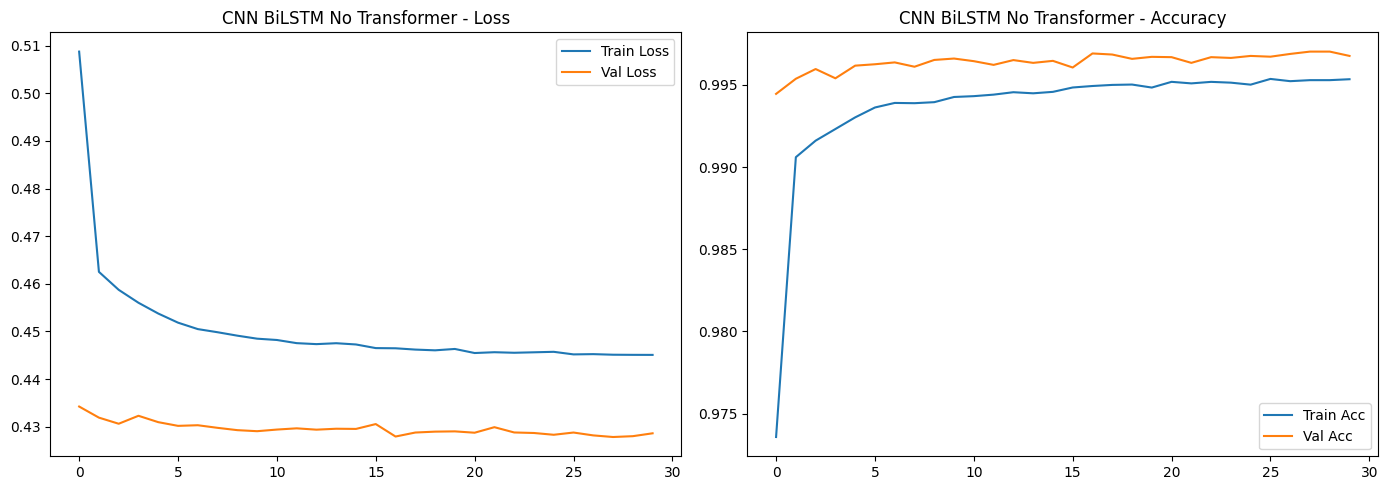

In [17]:
print("Training CNN+BiLSTM (No Transformer) Ablation Model...")
history_no_transformer = train_model(model_no_transformer, train_loader, val_loader, CONFIG['epochs'],
                                       save_path='cnn_bilstm_no_transformer_best.pth')
plot_history(history_no_transformer, "CNN BiLSTM No Transformer")

In [18]:
print("Fitting MinMax Gate for CNN+BiLSTM (No Transformer)...")
train_feats_nt, train_labels_nt = get_prob_features(model_no_transformer, train_loader, device, temperature=1.0)
gate_no_transformer = MinMaxThreeWayGate(q=15).fit(train_feats_nt, train_labels_nt)
print(f"Gate fitted. Train feats shape: {train_feats_nt.shape}")

Fitting MinMax Gate for CNN+BiLSTM (No Transformer)...
Gate fitted. Train feats shape: (496866, 6)



  EVALUATION: CNN + BiLSTM (No Transformer)

  Total test samples  : 408735
  Predicted Emerging  : 297565 (excluded)
  Evaluated samples   : 111170

  Accuracy : 0.9482
  Precision: 0.9038
  Recall   : 0.9482
  F1-Score : 0.9243

  Classification Report (Emerging excluded):
                        precision    recall  f1-score   support

                Benign       1.00      1.00      1.00     18924
DDoS_ACK_Fragmentation       1.00      1.00      1.00      4792
        DoS_HTTP_Flood       0.99      1.00      0.99      1121
         DoS_SYN_Flood       0.86      1.00      0.92     34364
         DoS_TCP_Flood       1.00      1.00      1.00     45756
         Mirai_udplain       0.00      0.00      0.00      5730
     VulnerabilityScan       0.84      1.00      0.91       483

              accuracy                           0.95    111170
             macro avg       0.81      0.86      0.83    111170
          weighted avg       0.90      0.95      0.92    111170



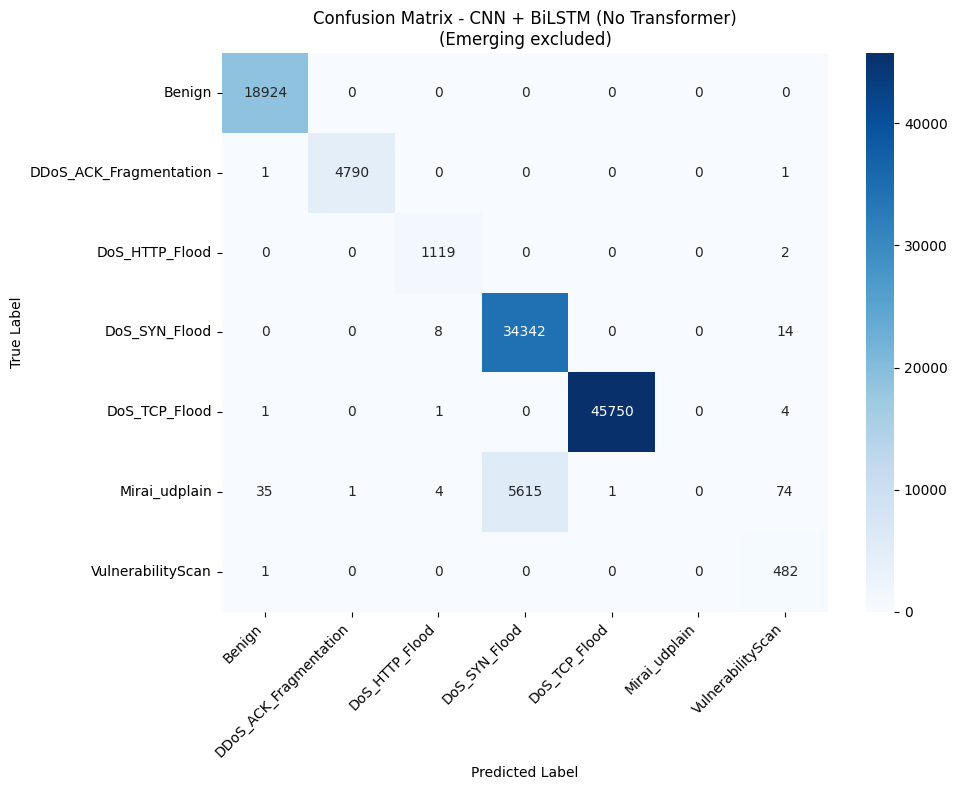

In [21]:
results_no_transformer = evaluate_model(model_no_transformer, test_loader, gate_no_transformer, le,
                                          y_test_final_str, "CNN + BiLSTM (No Transformer)")